# Session 9 — Inference and serving

Training happens once; a deployed model answers requests all day, and the cost and speed of each answer decide what a model is worth in practice. This session measures where the time and memory of generating text go, on our laptop GPU with Qwen2.5-0.5B and 1.5B: the cache that makes decoding affordable, the difference between reading a prompt and writing an answer, batching, attention memory, quantised weights, and a draft model that proposes tokens for a larger one to check.

**By the end of the session you should be able to:**

1. explain, with measurements, why decoding uses a cache, how large it is, and why decoding one request at a time leaves the GPU mostly idle;
2. compare naive attention with a fused kernel, and weight quantisation schemes, by memory, time and perplexity;
3. work out from measured step times whether speculative decoding can pay off on given hardware.

**To run it yourself** you need the packages from Session 6. The notebook uses Qwen2.5-0.5B-Instruct and Qwen2.5-1.5B-Instruct (about 1 and 3 GB, downloaded in Session 6). It took 1,489 s on our laptop GPU, on a machine shared with other work, so timings vary from run to run; the patterns are what matter. Section 2 compiles both models, which needs a working C compiler for PyTorch's compiler. On a CPU the timings would be very different and some cells would take hours.

In [1]:
import re, json, math, time, copy, numpy as np, pandas as pd, matplotlib.pyplot as plt
from aij_common import DEVICE, set_seed
import torch, torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoConfig
from transformers.utils import logging
import logging as pylogging; pylogging.getLogger("torch._inductor").setLevel(pylogging.ERROR)
logging.set_verbosity_error(); set_seed(0)
tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct", padding_side="left")
model = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct", dtype=torch.bfloat16).to(DEVICE).eval()
def chat_text(prompt): return tok.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
def sync(): torch.cuda.synchronize()
print(f"{torch.cuda.get_device_name()}, {torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GiB; Qwen2.5-0.5B-Instruct: {sum(p.numel() for p in model.parameters()) / 1e6:.0f}M parameters in bf16 = {sum(p.numel() * p.element_size() for p in model.parameters()) / 1e9:.2f} GB")

NVIDIA GeForce RTX 4070 Laptop GPU, 8.0 GiB; Qwen2.5-0.5B-Instruct: 494M parameters in bf16 = 0.99 GB


## 1. The KV cache

A decoder generates one token at a time, and each new token attends to all earlier ones. Without a cache, every step reruns the whole sequence through the model. With a **KV cache**, each layer keeps the keys and values it has already computed, so a step processes only the new token. We time 30 new tokens after contexts of 100 to 4,000 tokens (text from the basic course), with and without the cache, taking the best of three runs.

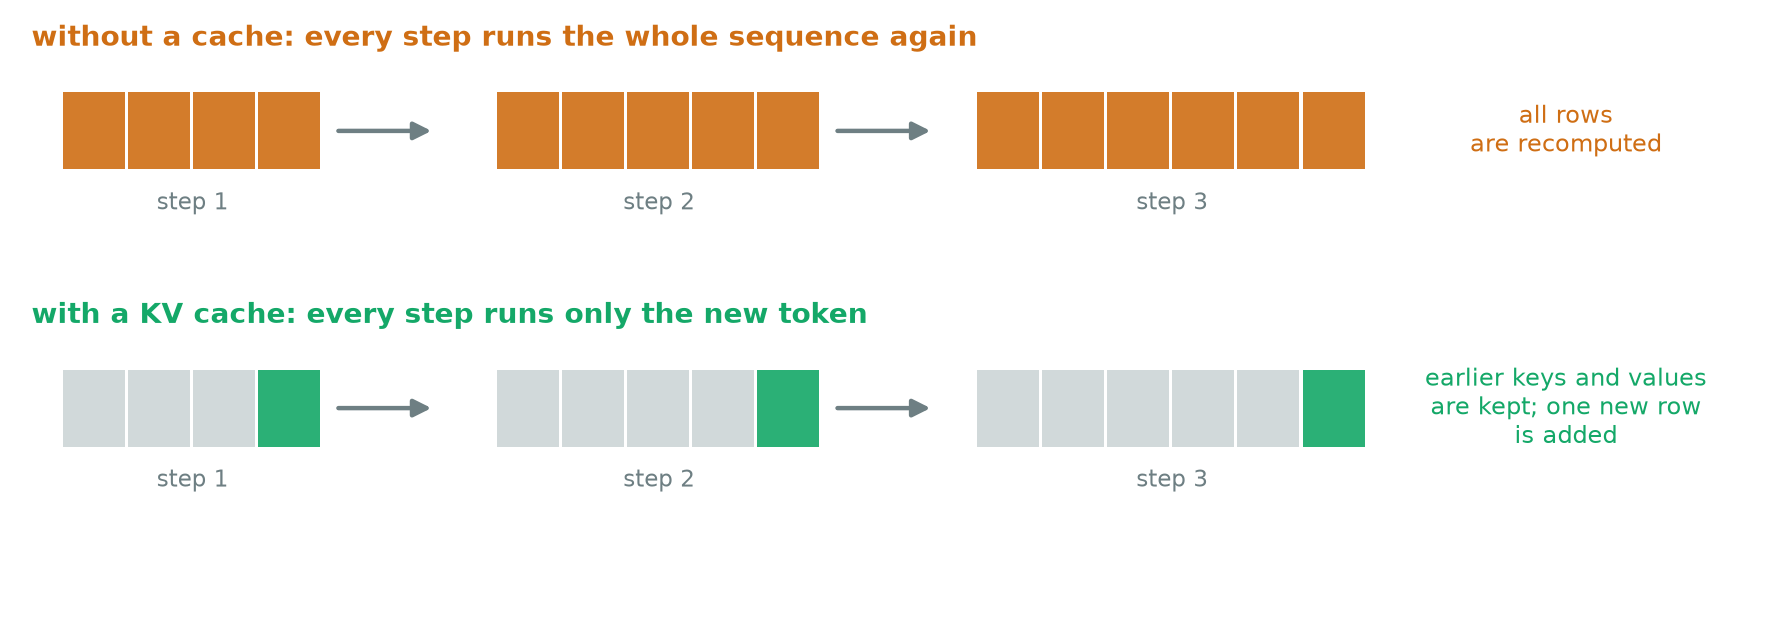

*Figure 9.1 — Why the cache helps. Without it, every step reruns the whole sequence through the model. With it, each layer keeps the keys and values it has already computed, so a step processes only the new token and adds one row.*

In [2]:
enc = tok([chat_text("Explain in a few sentences why a machine-learning project needs a separate validation set.")], return_tensors="pt").to(DEVICE)
@torch.no_grad()
def timed_generate(m, enc, n, reps=1, **kw):
    """Generate exactly n new tokens greedily; with reps > 1, run several times and keep the fastest (the machine is shared, so single timings are noisy)."""
    best = None
    for _ in range(reps):
        sync(); t = time.perf_counter(); out = m.generate(**enc, max_new_tokens=n, min_new_tokens=n, do_sample=False, pad_token_id=tok.pad_token_id, **kw); sync()
        best = min(best or 1e9, time.perf_counter() - t)
    return out[:, enc["input_ids"].shape[1]:], best
course_ids = tok("\n\n".join(json.loads(l)["text"] for l in open("data/basic_course_chunks.jsonl")), return_tensors="pt").input_ids.to(DEVICE)
timed_generate(model, enc, 8)                                                        # warm-up
rows = []
for L in (500, 2000, 8000):
    ctx = {"input_ids": course_ids[:, :L], "attention_mask": torch.ones(1, L, dtype=torch.long, device=DEVICE)}
    a, ta = timed_generate(model, ctx, 20, reps=3, use_cache=True); b, tb = timed_generate(model, ctx, 20, reps=3, use_cache=False)
    rows.append({"context (tokens)": L, "ms per new token, with cache": 1000 * ta / 20, "ms per new token, without": 1000 * tb / 20, "slow-down without cache": tb / ta,
                 "same 20 tokens": bool((a == b).all()), "first difference at": int((a != b).nonzero()[0, 1]) if (a != b).any() else None})
display(pd.DataFrame(rows).round(2))

,context (tokens),"ms per new token, with cache","ms per new token, without",slow-down without cache,same 20 tokens,first difference at
0,500,77.69,70.73,0.91,True,None
1,2000,73.84,81.72,1.11,True,None
2,8000,85.36,356.22,4.17,True,None


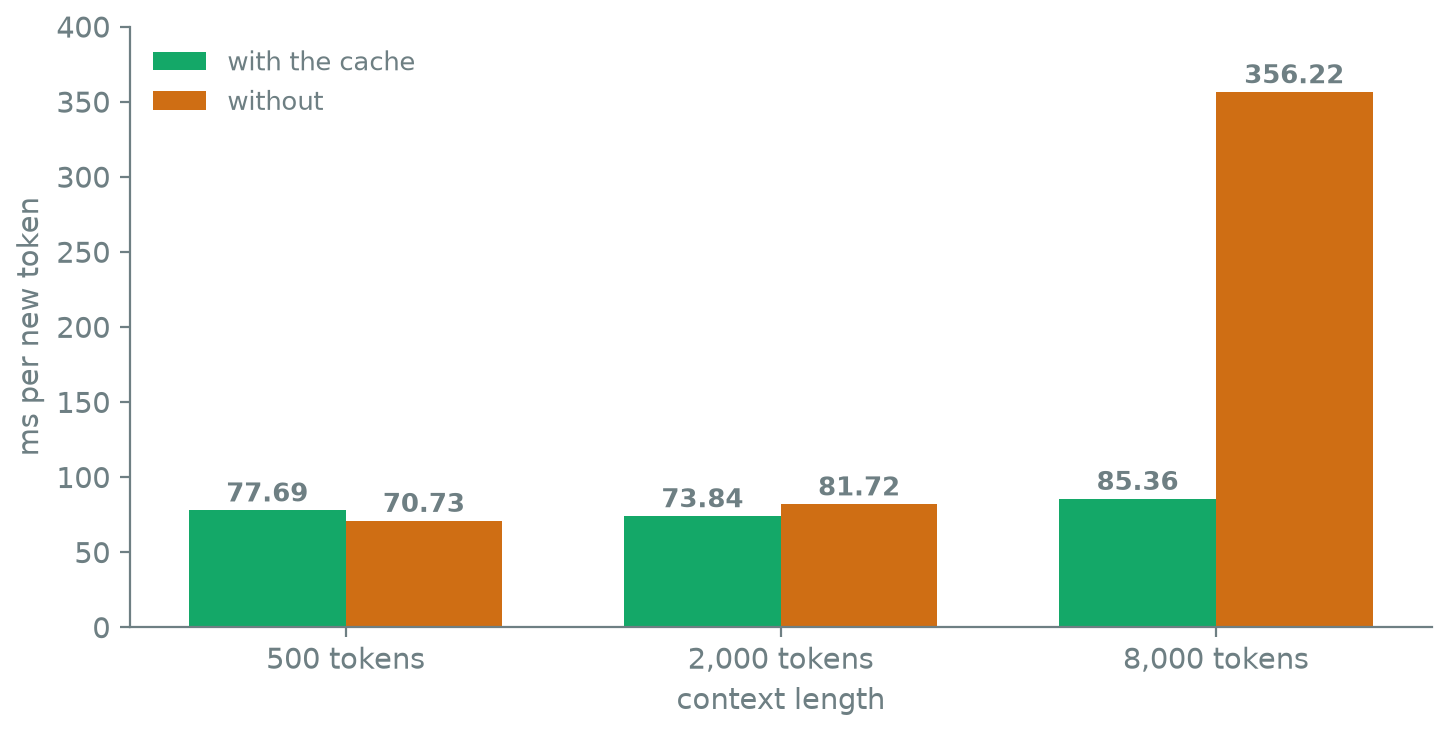

*Figure 9.2 — Milliseconds per new token with and without the cache, by context length. At 500 tokens the two are close (77.69 and 70.73); at 8000 tokens decoding without the cache takes 356.22 ms against 85.36.*

At 500 tokens of context the cache makes no visible difference (77.7 against 70.7 ms per token): rerunning a short sequence costs no more than the fixed cost of a step, which section 2 explains. As the context grows, recomputing it every step starts to dominate: at 8,000 tokens, decoding without the cache takes 356 ms per token against 85 ms with it, 4.2 times slower, and the gap keeps growing with length. Both ways give the same 20 tokens here. (In bf16 they can differ: tiny rounding differences between the two ways of computing can flip a near-tie, as section 5 shows.)

How large is the cache? The next cell measures it and compares it with the formula.

In [3]:
@torch.no_grad()
def cache_bytes(m, ids):
    pkv = m(input_ids=ids, use_cache=True).past_key_values
    layers = getattr(pkv, "layers", None)
    tensors = [t for l in layers for t in (l.keys, l.values)] if layers is not None else [t for kv in pkv for t in kv]
    return sum(t.numel() * t.element_size() for t in tensors), tensors[0].shape
cfg = model.config; head_dim = cfg.hidden_size // cfg.num_attention_heads
for L in (100, 1000, 4000):
    measured, shape = cache_bytes(model, torch.randint(0, 1000, (1, L), device=DEVICE))
    formula = 2 * cfg.num_hidden_layers * cfg.num_key_value_heads * head_dim * L * 2
    print(f"{L:5d} tokens: cache measured {measured / 1e6:6.1f} MB, formula 2 x {cfg.num_hidden_layers} layers x {cfg.num_key_value_heads} kv heads x {head_dim} x {L} tokens x 2 bytes = {formula / 1e6:6.1f} MB; one key tensor has shape {tuple(shape)}")

  100 tokens: cache measured    1.2 MB, formula 2 x 24 layers x 2 kv heads x 64 x 100 tokens x 2 bytes =    1.2 MB; one key tensor has shape (1, 2, 100, 64)
 1000 tokens: cache measured   12.3 MB, formula 2 x 24 layers x 2 kv heads x 64 x 1000 tokens x 2 bytes =   12.3 MB; one key tensor has shape (1, 2, 1000, 64)
 4000 tokens: cache measured   49.2 MB, formula 2 x 24 layers x 2 kv heads x 64 x 4000 tokens x 2 bytes =   49.2 MB; one key tensor has shape (1, 2, 4000, 64)


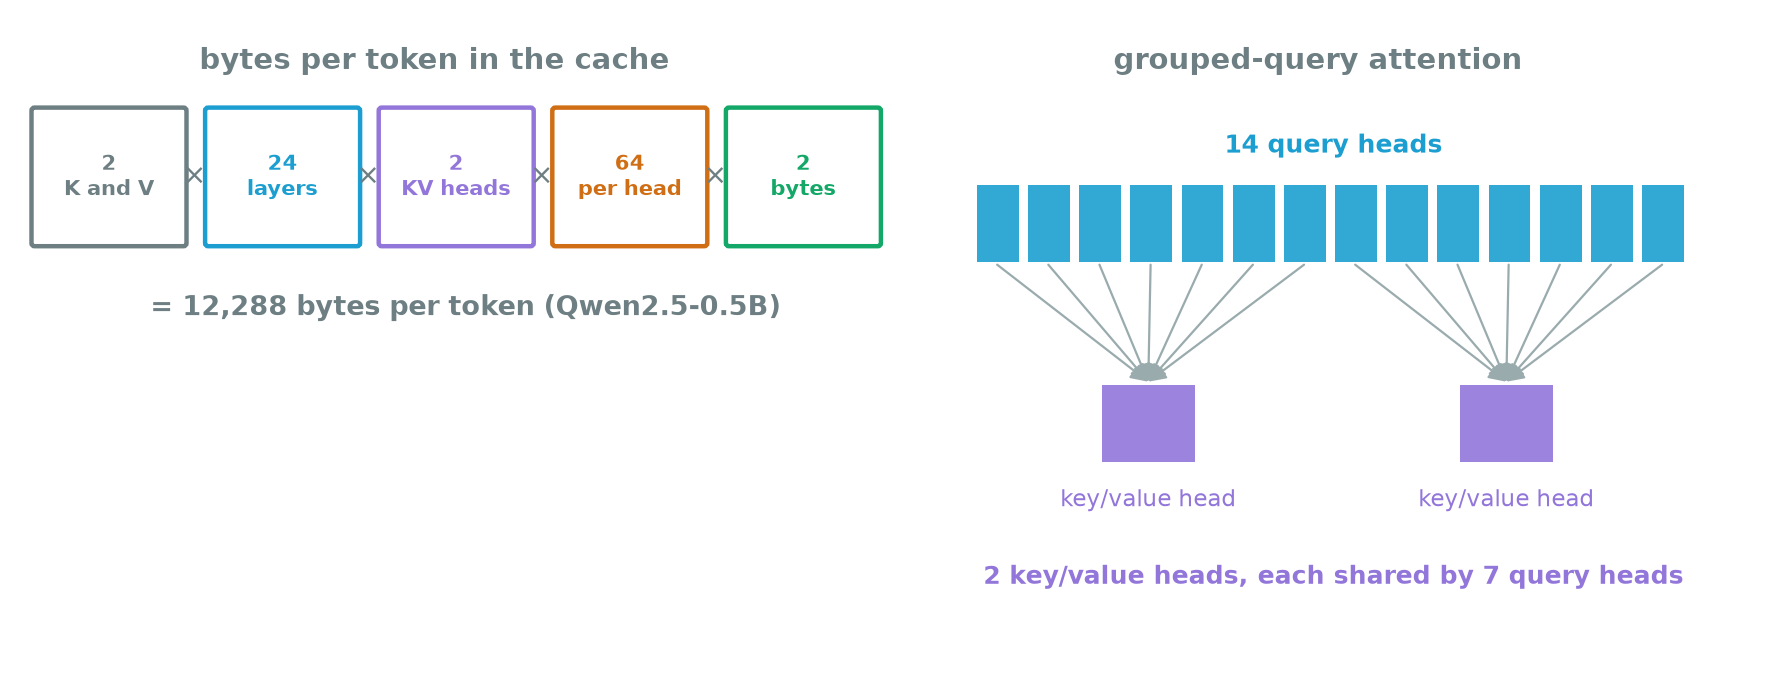

*Figure 9.3 — The size of the cache. Per token it is 2 for keys and values, times 24 layers, times 2 key/value heads, times 64 numbers per head, times 2 bytes, which is 12288 bytes. Grouped-query attention is what keeps 2 instead of 14: the 14 query heads share the 2 key/value heads.*

The cache size follows the formula exactly: 2 (keys and values) × 24 layers × 2 key/value heads × 64 numbers per head × 2 bytes, per token, so 49.2 MB at 4,000 tokens. It grows linearly with context and with the number of requests served at once, and for long contexts it is often what fills GPU memory.

Qwen keeps the cache small with **grouped-query attention**: its 14 query heads share 2 key/value heads. The next table compares the cache per token for three real models, read from their configuration files.

In [4]:
rows = []
for name in ("gpt2", "Qwen/Qwen2.5-0.5B-Instruct", "Qwen/Qwen2.5-1.5B-Instruct"):
    c = AutoConfig.from_pretrained(name); nl = getattr(c, "num_hidden_layers", getattr(c, "n_layer", None)); nh = getattr(c, "num_attention_heads", getattr(c, "n_head", None))
    d = getattr(c, "hidden_size", getattr(c, "n_embd", None)); kvh = getattr(c, "num_key_value_heads", nh); hd = d // nh
    per_tok = 2 * nl * kvh * hd * 2
    rows.append({"model": name.split("/")[-1], "layers": nl, "query heads": nh, "key/value heads": kvh, "head size": hd, "KV bytes per token": per_tok,
                 "cache for 4,096 tokens (MB)": per_tok * 4096 / 1e6, "same with one kv head per query head (MB)": 2 * nl * nh * hd * 2 * 4096 / 1e6})
display(pd.DataFrame(rows).round(1))

,model,layers,query heads,key/value heads,head size,KV bytes per token,"cache for 4,096 tokens (MB)",same with one kv head per query head (MB)
0,gpt2,12,12,12,64,36864,151.0,151.0
1,Qwen2.5-0.5B-Instruct,24,14,2,64,12288,50.3,352.3
2,Qwen2.5-1.5B-Instruct,28,12,2,128,28672,117.4,704.6


GPT-2 small has one key/value head per query head, 36,864 bytes per token. Qwen2.5-0.5B is a larger model with twice the layers, yet needs a third of that, 12,288 bytes, because 7 query heads share each key/value head. With one key/value head per query head it would need 352 MB at 4,096 tokens instead of 50 MB; for the 1.5B model, 705 MB instead of 117 MB.

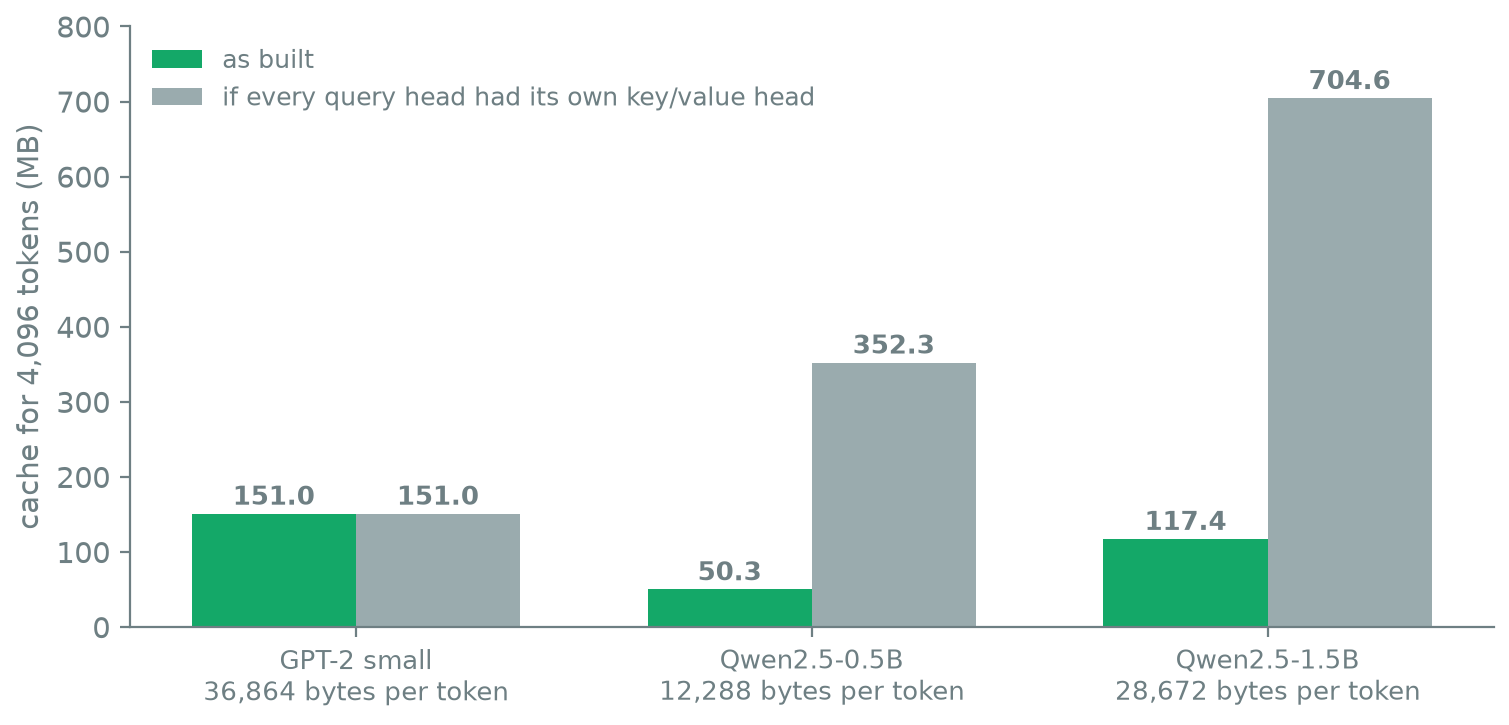

*Figure 9.4 — Cache for 4,096 tokens, as built and with one key/value head per query head. GPT-2 small is 151.0 MB either way; Qwen2.5-0.5B is 50.3 MB instead of 352.3, and Qwen2.5-1.5B is 117.4 MB instead of 704.6.*

## 2. Where the time goes

Generating an answer has two phases. **Prefill** reads the prompt, all tokens at once. **Decode** writes the answer, one token per step.

> **Pause:** reading a 1,000-token prompt and writing one token both take one pass through the model. Which takes longer?
>
> - **A.** Reading the prompt, by a factor of about a thousand.
> - **B.** Writing one token, by a little.
> - **C.** They take about the same time.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**B.** Prefilling 1,000 tokens takes 64.0 ms and decoding one token takes 81.2 ms. Per token, prefill is more than a thousand times faster.

</details>

In [5]:
@torch.no_grad()
def prefill_time(m, L, reps=5):
    ids = torch.randint(0, 1000, (1, L), device=DEVICE); m(input_ids=ids)
    times = []
    for _ in range(reps): sync(); t = time.perf_counter(); m(input_ids=ids); sync(); times.append(time.perf_counter() - t)
    return min(times)
_, t_dec = timed_generate(model, enc, 200, reps=3); per_tok = t_dec / 200
for L in (100, 1000, 4000):
    tp = prefill_time(model, L); print(f"prefill of {L:5d} tokens: {1000 * tp:6.1f} ms = {L / tp:9,.0f} tokens/s")
print(f"decoding one token at a time: {1000 * per_tok:.1f} ms per token = {1 / per_tok:.0f} tokens/s")

prefill of   100 tokens:   73.3 ms =     1,365 tokens/s


prefill of  1000 tokens:   64.0 ms =    15,631 tokens/s


prefill of  4000 tokens:  178.8 ms =    22,367 tokens/s
decoding one token at a time: 81.2 ms per token = 12 tokens/s


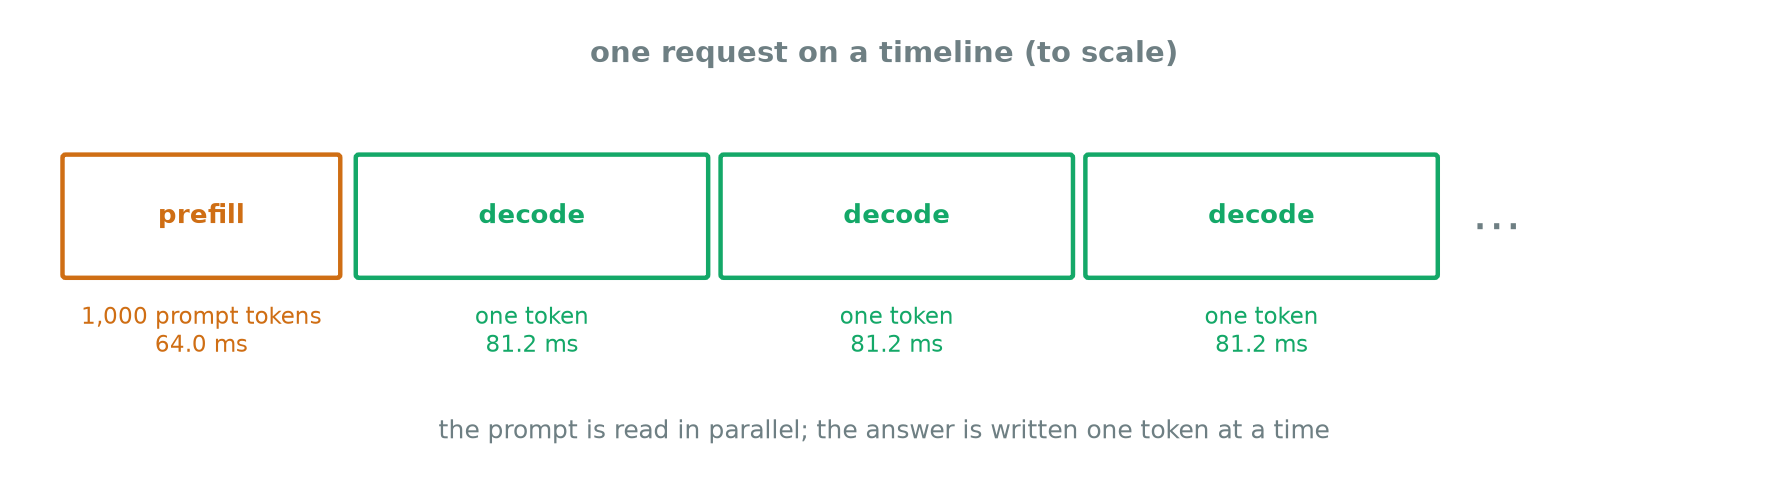

*Figure 9.5 — One request on a timeline, drawn to scale. Prefilling the 1,000-token prompt takes 64.0 ms; each decoded token then takes 81.2 ms.*

Prefilling 1,000 tokens takes 64 ms, less than the 81 ms of decoding a single token, and processes 15,631 tokens per second; at 4,000 tokens, 179 ms. Decoding produces 12 tokens per second. Per token, prefill is more than a thousand times faster, because the GPU processes all prompt tokens in parallel, while decoding has to wait for each token before it can compute the next.

A step that handles one token leaves most of the GPU idle, which suggests the first fix: serve several requests in the same step.

,batch size,time for 100 new tokens (s),"tokens/s, all requests","tokens/s, each request"
0,1,8.7,11.5,11.5
1,4,7.6,52.7,13.2
2,16,9.4,169.9,10.6
3,64,8.9,718.0,11.2


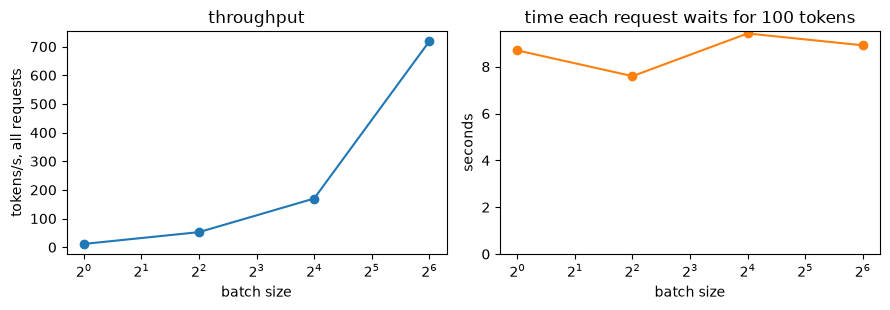

In [6]:
prompts = [chat_text(f"Write a short paragraph about {t}.") for t in ["robots", "batteries", "rivers", "chess", "bread", "volcanoes", "trains", "owls"] * 8]
rows = []
for bs in (1, 4, 16, 64):
    e = tok(prompts[:bs], return_tensors="pt", padding=True).to(DEVICE); _, t = timed_generate(model, e, 100, reps=3)
    rows.append({"batch size": bs, "time for 100 new tokens (s)": t, "tokens/s, all requests": bs * 100 / t, "tokens/s, each request": 100 / t})
bt = pd.DataFrame(rows); display(bt.round(1))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(bt["batch size"], bt["tokens/s, all requests"], "o-"); ax[0].set_xscale("log", base=2); ax[0].set_xlabel("batch size"); ax[0].set_ylabel("tokens/s, all requests"); ax[0].set_title("throughput")
ax[1].plot(bt["batch size"], bt["time for 100 new tokens (s)"], "o-", color="C1"); ax[1].set_xscale("log", base=2); ax[1].set_ylim(0, None); ax[1].set_xlabel("batch size"); ax[1].set_ylabel("seconds"); ax[1].set_title("time each request waits for 100 tokens")
plt.tight_layout(); plt.show()

Going from 1 request to 64 multiplies throughput by 62, from 11.5 to 718 tokens per second, while each request still waits about the same time for its 100 tokens (8.7 against 8.9 s). For a server this is close to free capacity: one step with 64 sequences costs about as much as one step with a single sequence. Real servers go further with **continuous batching**, adding new requests to the batch as soon as others finish.

Why does a step cost the same regardless of batch size? The next cell compares the time per step with the time it takes just to read the weights from memory.

In [7]:
buf = torch.empty(256 * 2**20, dtype=torch.uint8, device=DEVICE); buf.clone(); sync(); t = time.perf_counter()
for _ in range(20): buf.clone()
sync(); copy_gbs = 20 * 2 * buf.numel() / (time.perf_counter() - t) / 1e9; del buf
print(f"copying 256 MB on this GPU: {copy_gbs:.0f} GB/s (counting the read and the write)")
big = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-1.5B-Instruct", dtype=torch.bfloat16).to(DEVICE).eval(); timed_generate(big, enc, 8)
rows, step_ms = [], {}
for name, m in (("0.5B", model), ("1.5B", big)):
    nbytes = sum(p.numel() * p.element_size() for p in m.parameters()); _, t_eager = timed_generate(m, enc, 100, reps=3)
    t0 = time.perf_counter(); timed_generate(m, enc, 100, cache_implementation="static"); compile_s = time.perf_counter() - t0      # the first call compiles the model
    _, t_comp = timed_generate(m, enc, 100, reps=3, cache_implementation="static"); step_ms[name] = 1000 * t_eager / 100
    rows.append({"model": name, "weights (GB)": nbytes / 1e9, "ms per token": 1000 * t_eager / 100, "weights read (GB/s)": nbytes / (t_eager / 100) / 1e9,
                 "compiled: ms per token": 1000 * t_comp / 100, "compiled: weights read (GB/s)": nbytes / (t_comp / 100) / 1e9, "first compiled call (s)": compile_s})
display(pd.DataFrame(rows).round(2))
del big; model._cache = None; torch._dynamo.reset(); torch.cuda.empty_cache()      # free the 1.5B model and the compiled state before the attention test; the 1.5B is reloaded for section 5

copying 256 MB on this GPU: 209 GB/s (counting the read and the write)


,model,weights (GB),ms per token,weights read (GB/s),compiled: ms per token,compiled: weights read (GB/s),first compiled call (s)
0,0.5B,0.99,72.15,13.70,12.45,79.36,20.75
1,1.5B,3.09,85.12,36.27,32.94,93.74,72.18


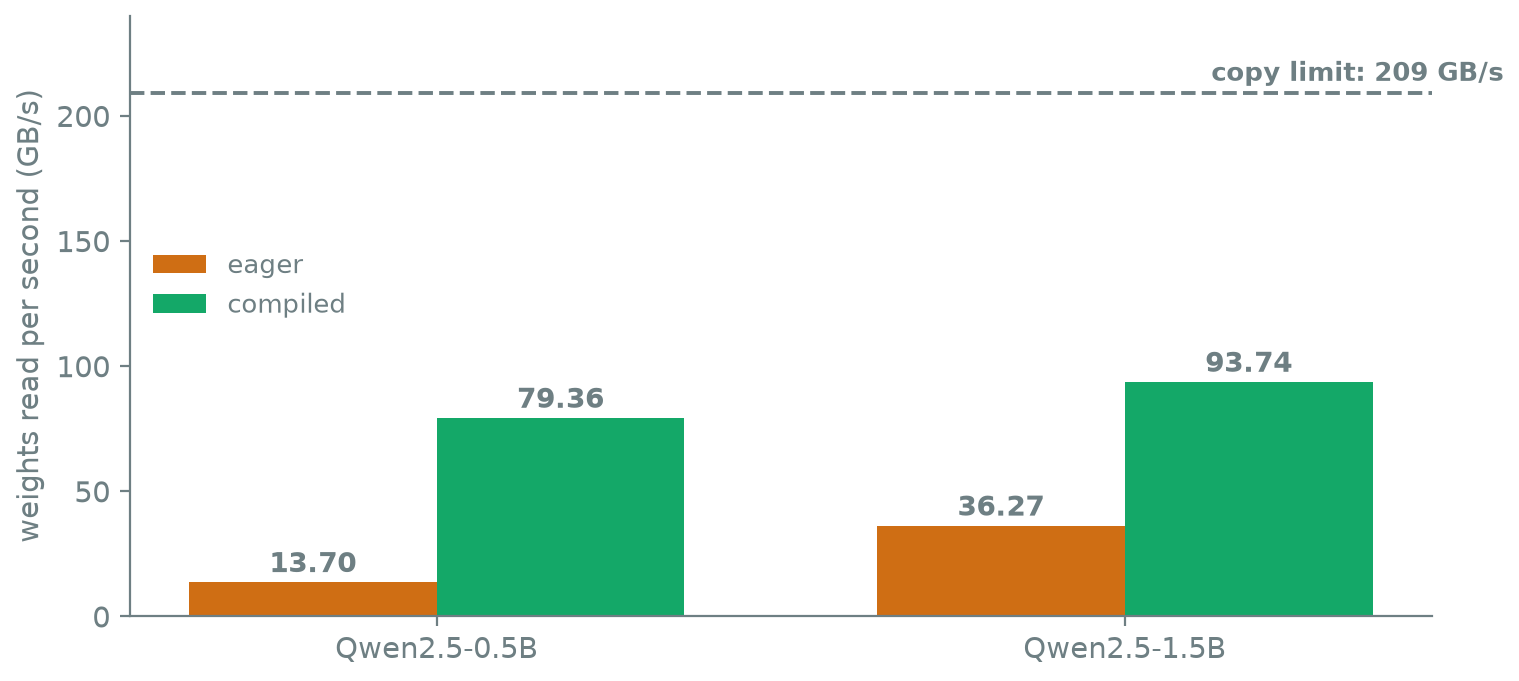

*Figure 9.6 — Weights read per second while decoding one token at a time, against the 209 GB/s the GPU manages when copying memory. Eager decoding reads 13.70 and 36.27 GB/s for the 0.5B and 1.5B models; compiled decoding reads 79.36 and 93.74.*

This GPU copies memory at 209 GB/s. A decoding step must read every weight once, so the 0.5B model (0.99 GB) cannot take less than about 5 ms per token, and the 1.5B (3.09 GB) about 15 ms. Running normally ("eager"), they take 72 and 85 ms: the GPU reads weights at only 14 and 36 GB/s. Most of each step is spent waiting for the CPU, which launches hundreds of small GPU operations one after another, each with a fixed overhead (large on WSL, where these runs are made).

Compiling the model with a static cache removes most of that overhead: PyTorch records the whole step once and replays it as a single CUDA graph. After a first call that compiles (21 and 72 s), the 0.5B model needs 12.5 ms per token and the 1.5B 32.9 ms, reading weights at 79 and 94 GB/s. Compiled decoding moves towards the memory limit; eager decoding at batch 1 is nowhere near it. That is also why batching was almost free: the extra sequences use compute that was idle anyway.

These timings come from a laptop shared with other work, so they vary between runs; the ratios are what to take from the table.

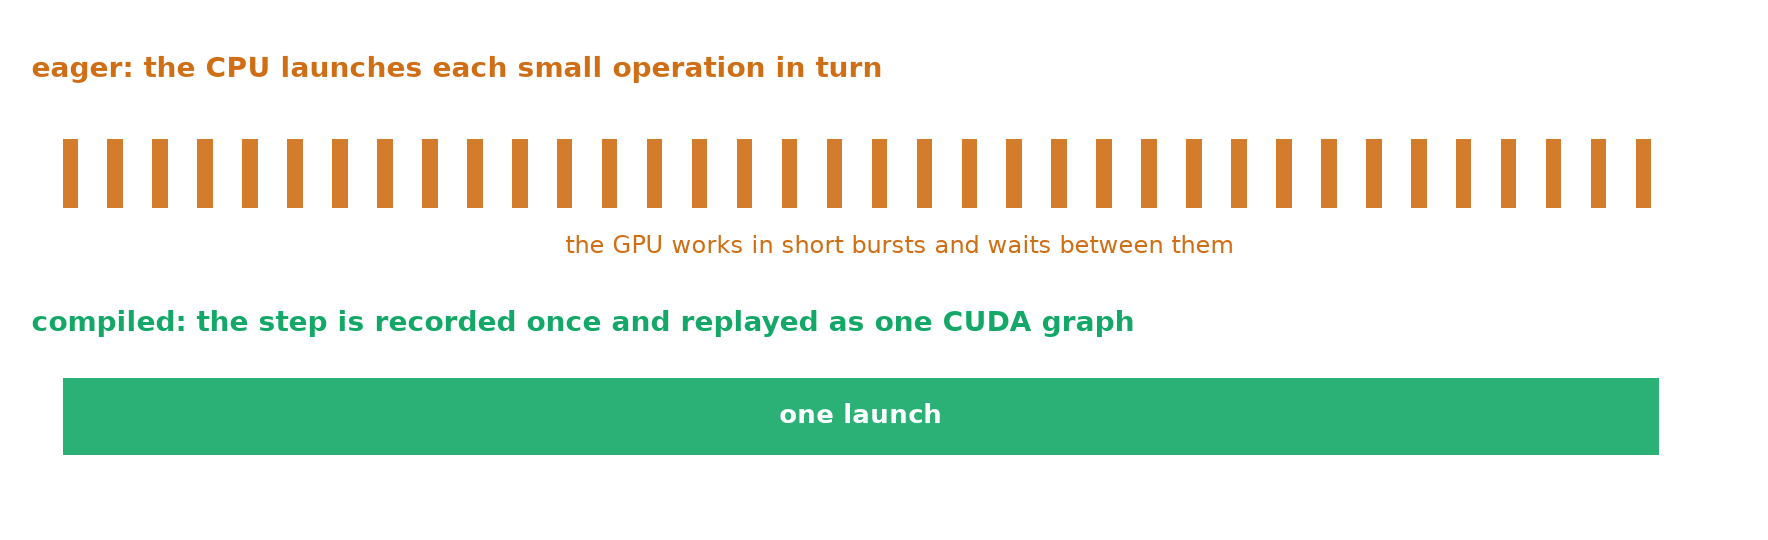

*Figure 9.7 — Why compiling helps. Run normally, a step is hundreds of small operations launched one after another, each with a fixed overhead. Compiled, the whole step is recorded once and replayed as a single CUDA graph.*

## 3. Attention memory

Written directly, attention builds a score matrix with one entry per pair of positions, for every head: memory grows with the square of the sequence length. Fused kernels such as PyTorch's `scaled_dot_product_attention` (SDPA, which uses FlashAttention-style algorithms on GPUs) compute the same result in blocks and never store the full matrix. We compare the two on random queries, keys and values with 14 heads of size 64, as in the 0.5B model.

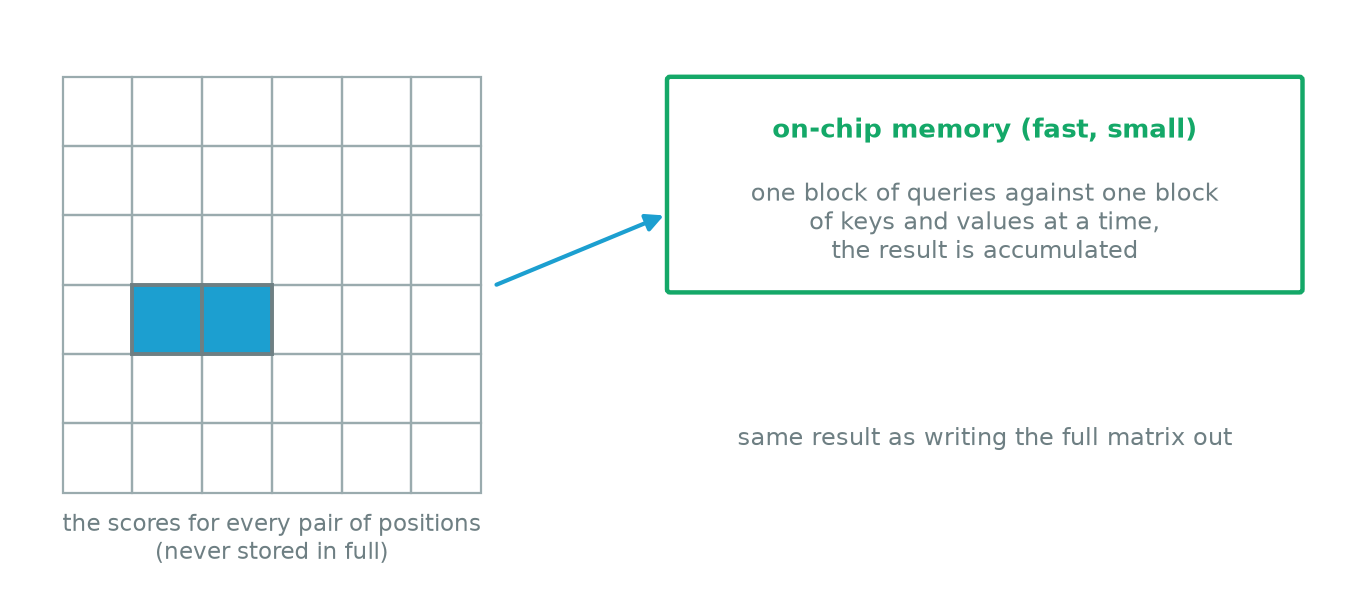

*Figure 9.8 — The idea behind fused attention. The full table of scores is never written out; a block of queries is compared with a block of keys and values in fast on-chip memory, and the result is accumulated block by block.*

In [8]:
def naive_attention(q, k, v):
    s = (q @ k.transpose(-2, -1)) / math.sqrt(q.shape[-1]); L = s.shape[-1]
    s = s.masked_fill(torch.triu(torch.ones(L, L, dtype=torch.bool, device=q.device), 1), float("-inf"))
    return s.softmax(-1) @ v
def measure(fn, q, k, v):
    fn(q, k, v); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(); base = torch.cuda.memory_allocated()
    sync(); t = time.perf_counter(); out = fn(q, k, v); sync(); dt = time.perf_counter() - t
    return out, dt, (torch.cuda.max_memory_allocated() - base) / 2**20
rows = []
for L in (512, 1024, 2048, 4096, 8192):
    q, k, v = (torch.randn(1, 14, L, 64, device=DEVICE, dtype=torch.bfloat16) for _ in range(3))          # 14 heads of size 64, as in the 0.5B model
    o1, t1, m1 = measure(naive_attention, q, k, v); o2, t2, m2 = measure(lambda q, k, v: F.scaled_dot_product_attention(q, k, v, is_causal=True), q, k, v)
    rows.append({"sequence length": L, "naive: extra memory (MiB)": m1, "naive: ms": 1000 * t1, "SDPA: extra memory (MiB)": m2, "SDPA: ms": 1000 * t2, "largest difference": (o1.float() - o2.float()).abs().max().item()})
    del o1, o2, q, k, v
at = pd.DataFrame(rows); display(at.round(3))

,sequence length,naive: extra memory (MiB),naive: ms,SDPA: extra memory (MiB),SDPA: ms,largest difference
0,512,14.875,14.948,0.903,0.581,0.016
1,1024,57.750,16.809,1.806,0.593,0.016
2,2048,228.000,15.086,3.610,0.782,0.016
3,4096,912.000,66.139,7.220,1.514,0.016
4,8192,3648.000,424.343,14.438,4.494,0.016


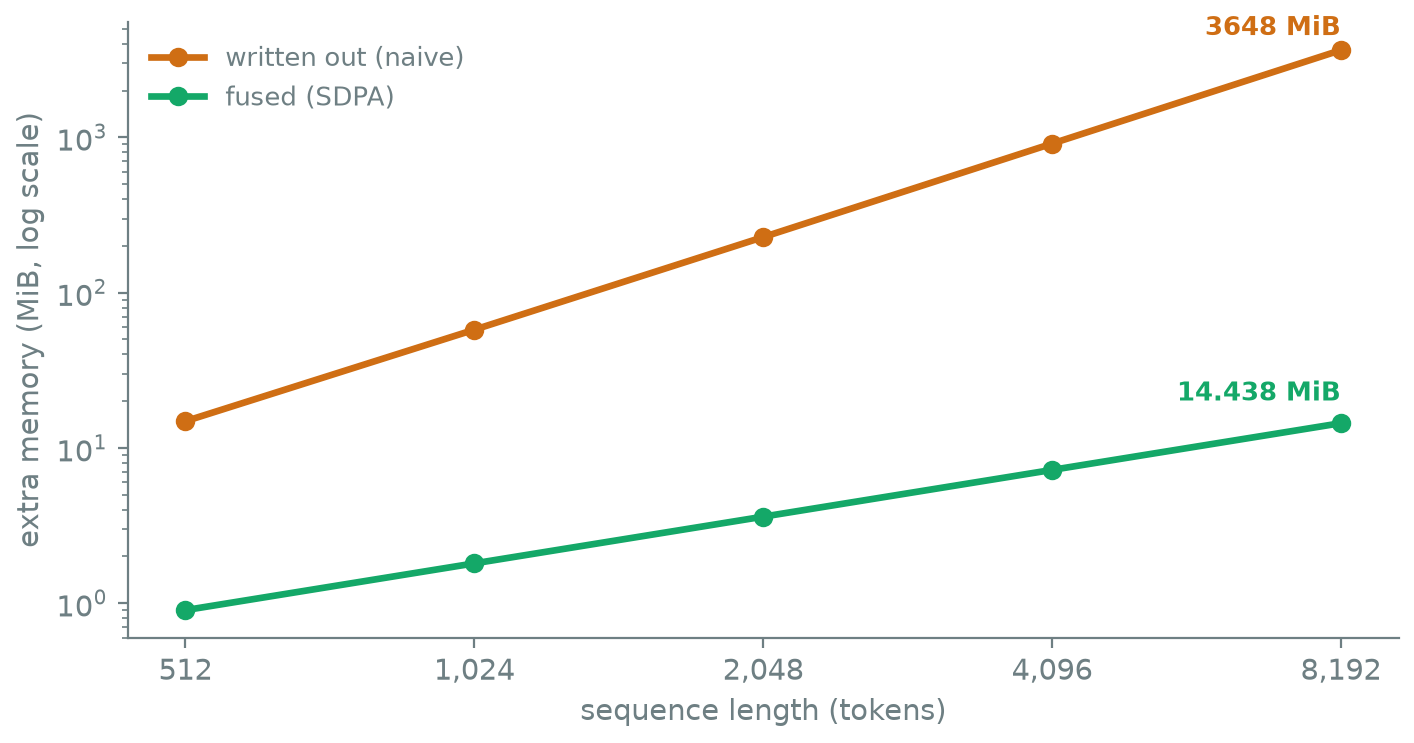

*Figure 9.9 — Extra memory for one attention layer, written out against fused, by sequence length on log axes. The naive version grows with the square of the length, from 14.875 MiB at 512 tokens to 3648 MiB at 8192; the fused version stays at 14.438 MiB at 8192 tokens.*

The two give the same result to within bf16 rounding (largest difference 0.016). The naive version's extra memory grows with the square of the length: 15 MiB at 512 tokens, 912 MiB at 4,096 and 3,648 MiB at 8,192, almost half this GPU's memory for one layer of one sequence. SDPA needs 14 MiB at 8,192 tokens and takes 4.5 ms against 424 ms. (Below 4,096 tokens the times are small enough that noise from other work on the machine dominates.)

## 4. Quantised weights

Decode speed is limited by reading the weights, and the weights also set how large a model fits in memory, so storing them in fewer bits helps on both counts. **Round-to-nearest quantisation** stores each weight as a small integer times a scale: for 4 bits, an integer from −8 to 7. The question is how many weights share one scale. We quantise the 168 weight matrices inside the 0.5B model's blocks in four ways and measure perplexity on 40 windows of 512 tokens of the basic-course text.

> **Pause:** int4 with one scale for a whole matrix uses the same 4 bits per weight as int4 with one scale per row. How different can they be?
>
> - **A.** About the same.
> - **B.** A few percent worse.
> - **C.** The per-matrix version destroys the model.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**C.** One scale per row gives a perplexity of 30.08, against 15.47 for the original. One scale per matrix gives 150,177,071.15, worse than guessing.

</details>

In [9]:
eval_text = "\n\n".join(json.loads(l)["text"] for l in open("data/basic_course_chunks.jsonl"))
eval_ids = tok(eval_text, return_tensors="pt").input_ids[0]; W = 512; windows = eval_ids[: (len(eval_ids) // W) * W].view(-1, W)[:40].to(DEVICE)
@torch.no_grad()
def perplexity(m):
    losses = [F.cross_entropy(m(input_ids=windows[i:i + 2]).logits[:, :-1].float().reshape(-1, m.config.vocab_size), windows[i:i + 2, 1:].reshape(-1)).item() for i in range(0, len(windows), 2)]
    return math.exp(np.mean(losses))
def quantise(w, bits, group=None):
    """Round-to-nearest symmetric quantisation. group=None: one scale per output row; group=0: one scale for the whole matrix; group=g: one scale per g weights in a row."""
    qmax = 2 ** (bits - 1) - 1; w32 = w.float()
    if group == 0: scale = w32.abs().max() / qmax; return (torch.round(w32 / scale).clamp(-qmax - 1, qmax) * scale).to(w.dtype)
    shaped = w32.view(w.shape[0], -1, group) if group else w32.unsqueeze(1)
    scale = shaped.abs().amax(-1, keepdim=True).clamp(min=1e-8) / qmax
    return (torch.round(shaped / scale).clamp(-qmax - 1, qmax) * scale).view_as(w32).to(w.dtype)
linears = {n: mod for n, mod in model.model.layers.named_modules() if isinstance(mod, torch.nn.Linear)}
original = {n: mod.weight.detach().clone() for n, mod in linears.items()}
n_q = sum(w.numel() for w in original.values())
print(f"{len(windows)} windows of {W} tokens from the basic-course text; quantising the {len(linears)} weight matrices inside the blocks ({n_q / 1e6:.0f}M of the {sum(p.numel() for p in model.parameters()) / 1e6:.0f}M parameters; the embedding stays in bf16)")
rows = [{"weights": "bf16 (original)", "bits per weight": 16, "perplexity": perplexity(model)}]
for label, bits, group, extra in (("int8, one scale per row", 8, None, 0), ("int4, one scale per row", 4, None, 0), ("int4, one scale per 128 weights", 4, 128, 16 / 128), ("int4, one scale per matrix", 4, 0, 0)):
    with torch.no_grad():
        for n, mod in linears.items(): mod.weight.copy_(quantise(original[n], bits, group))
    rows.append({"weights": label, "bits per weight": bits + extra, "perplexity": perplexity(model)})
with torch.no_grad():
    for n, mod in linears.items(): mod.weight.copy_(original[n])
qt = pd.DataFrame(rows); qt["perplexity"] = qt["perplexity"].map(lambda x: f"{x:,.2f}"); display(qt)

40 windows of 512 tokens from the basic-course text; quantising the 168 weight matrices inside the blocks (358M of the 494M parameters; the embedding stays in bf16)


,weights,bits per weight,perplexity
0,bf16 (original),16.000,15.47
1,"int8, one scale per row",8.000,15.45
2,"int4, one scale per row",4.000,30.08
3,"int4, one scale per 128 weights",4.125,21.22
4,"int4, one scale per matrix",4.000,"150,177,071.15"


int8 with one scale per row is indistinguishable from the original (perplexity 15.45 against 15.47). At 4 bits the choice of scale decides everything. One scale per matrix destroys the model: perplexity 150 million, far worse than guessing uniformly among the 151,936 tokens of the vocabulary. One scale per row doubles the perplexity to 30.08. One scale per 128 weights brings it down to 21.22, at the cost of 0.125 extra bits per weight to store the scales.

block 1, MLP down projection (896, 4864): largest |weight| 0.305, typical (RMS) 0.0182, ratio 17
ratio of each row's largest weight to its RMS: median 4.1, largest 21
int4, one scale per matrix  : rounding error = 66% of the typical weight
int4, one scale per row     : rounding error = 20% of the typical weight
int4, one scale per 128     : rounding error = 13% of the typical weight


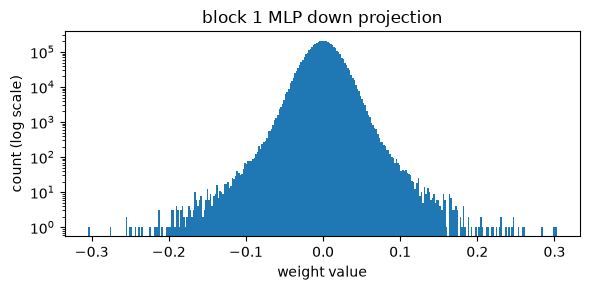

In [10]:
w = original["0.mlp.down_proj"].float(); row_max, row_rms = w.abs().amax(1), w.pow(2).mean(1).sqrt()
print(f"block 1, MLP down projection {tuple(w.shape)}: largest |weight| {w.abs().max():.3f}, typical (RMS) {w.pow(2).mean().sqrt():.4f}, ratio {w.abs().max() / w.pow(2).mean().sqrt():.0f}")
print(f"ratio of each row's largest weight to its RMS: median {(row_max / row_rms).median():.1f}, largest {(row_max / row_rms).max():.0f}")
for label, group in (("one scale per matrix", 0), ("one scale per row", None), ("one scale per 128", 128)):
    e = (quantise(w, 4, group) - w).pow(2).mean().sqrt() / w.pow(2).mean().sqrt(); print(f"int4, {label:22s}: rounding error = {100 * e:.0f}% of the typical weight")
plt.figure(figsize=(6, 3)); plt.hist(w.flatten().cpu().numpy(), bins=300, log=True); plt.xlabel("weight value"); plt.ylabel("count (log scale)"); plt.title("block 1 MLP down projection"); plt.tight_layout(); plt.show()

The reason is outliers. In block 1's MLP down projection the largest weight is 0.305, 17 times the typical size (0.0182). With one scale per matrix, the 16 levels of int4 must stretch to cover ±0.305, so the steps are about 0.04 apart and most ordinary weights round to zero: the rounding error is 66% of a typical weight. One scale per row only has to cover that row's largest weight (typically 4.1 times the row's typical size, at most 21), and the error falls to 20%; one scale per 128 weights, 13%. The histogram, on a log scale, shows the shape: a narrow peak around zero and a few weights far out in the tails.

Methods used in practice go further, choosing how to round so that each layer's output changes as little as possible (Going deeper).

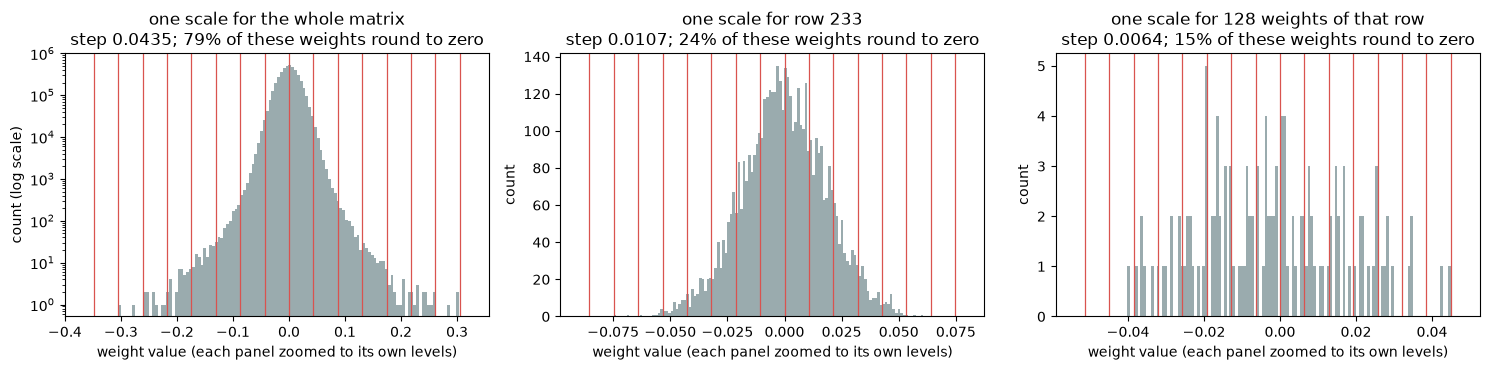

largest weight 0.305, typical (RMS) 0.0182; share of all weights that round to zero with one scale per matrix: 79%, per row: 27%


In [11]:
# Figure 9.10: where the 16 int4 levels fall on real weights, for three ways of choosing the scale
w = original["0.mlp.down_proj"].float().cpu()
row = int(torch.argsort((w.abs().amax(1) / w.pow(2).mean(1).sqrt()))[len(w) // 2])            # a row with a typical outlier ratio
group = w[row, :128]
def levels(scale): return np.arange(-8, 8) * scale
panels = [("one scale for the whole matrix", w.flatten(), w.abs().max().item() / 7), (f"one scale for row {row}", w[row], w[row].abs().max().item() / 7), ("one scale for 128 weights of that row", group, group.abs().max().item() / 7)]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (title, values, step) in zip(axes, panels):
    v = values.numpy(); zero_share = float((np.abs(v) < step / 2).mean())
    ax.hist(v, bins=120, color="#9AABAE", log=title.startswith("one scale for the whole"))
    for lv in levels(step): ax.axvline(lv, color="#D9534F", lw=0.9)
    ax.set(title=f"{title}\nstep {step:.4f}; {zero_share:.0%} of these weights round to zero", xlabel="weight value (each panel zoomed to its own levels)", xlim=(-9.2 * step, 8.2 * step))
axes[0].set_ylabel("count (log scale)"); axes[1].set_ylabel("count"); axes[2].set_ylabel("count")
plt.tight_layout(); plt.show()
print(f"largest weight {w.abs().max():.3f}, typical (RMS) {w.pow(2).mean().sqrt():.4f}; share of all weights that round to zero with one scale per matrix: {float((w.abs() < w.abs().max() / 14).float().mean()):.0%}, per row: {float((w.abs() < (w.abs().amax(1, keepdim=True) / 14)).float().mean()):.0%}")

*Figure 9.10 — The 16 int4 levels (vertical lines) laid over real weights from block 1's MLP down projection. Left: one scale for the whole matrix, set by its single largest weight, so the steps are wide and most ordinary weights land on the zero level. Middle: the scale of one row, set by that row's largest weight. Right: one scale for one group of 128 weights. Each panel is zoomed to its own range of levels. The share of weights that round to exactly zero is printed above each panel.*

## 5. Speculative decoding

Decoding is slow because each step does little work. **Speculative decoding** lets a small draft model propose several tokens, and the large model checks them all in one pass, keeping the ones it agrees with plus one token of its own. With greedy decoding the output is in principle identical to the large model's alone. We use the 0.5B model as draft for the 1.5B on eight prompts, timing Hugging Face's assisted generation and also running a hand-written loop with 4 draft tokens per round to count how many are accepted.

In [12]:
spec_questions = ["Explain what a learning rate is.", "List three uses of a robot vacuum.", "What is the capital of Japan, and what is it known for?", "Write a haiku about rain.",
                                        "Explain overfitting to a beginner.", "Give a recipe for pancakes.", "Why is the sky blue?", "Summarise the rules of chess in a few sentences."]
spec_prompts = [chat_text(p) for p in spec_questions]
@torch.no_grad()
def speculative_acceptance(target, draft, text, n=128, k=4):
    """Greedy speculative decoding written out: the draft proposes k tokens, the target checks them all in one pass and keeps the agreeing prefix plus one token of its own."""
    ids = tok([text], return_tensors="pt").input_ids.to(DEVICE); start, proposed, accepted, target_calls = ids.shape[1], 0, 0, 0
    while ids.shape[1] - start < n:
        d = draft.generate(ids, max_new_tokens=k, do_sample=False, pad_token_id=tok.pad_token_id)[:, ids.shape[1]:]
        t_pred = target(torch.cat([ids, d], 1)).logits[0, ids.shape[1] - 1:].argmax(-1); target_calls += 1
        agree = int((t_pred[:d.shape[1]] == d[0]).long().cumprod(0).sum()); proposed += d.shape[1]; accepted += agree
        ids = torch.cat([ids, d[:, :agree], t_pred[agree:agree + 1].view(1, 1)], 1)
    return accepted / proposed, (ids.shape[1] - start) / target_calls, ids[0, start:start + n]
big = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-1.5B-Instruct", dtype=torch.bfloat16).to(DEVICE).eval()
def first_diff(a, b): d = (a[:min(len(a), len(b))] != b[:min(len(a), len(b))]).nonzero(); return int(d[0, 0]) if len(d) else None
rows = []
for q_, p in zip(spec_questions, spec_prompts):
    e = tok([p], return_tensors="pt").to(DEVICE)
    plain, t_plain = timed_generate(big, e, 128, reps=2); assisted, t_assist = timed_generate(big, e, 128, reps=2, assistant_model=model)
    acc, per_call, mine = speculative_acceptance(big, model, p)
    rows.append({"prompt": q_[:40], "draft tokens accepted": acc, "tokens per target pass": per_call, "1.5B alone (s)": t_plain, "with 0.5B draft (s)": t_assist, "speed-up": t_plain / t_assist,
                 "assisted output first differs at": first_diff(plain[0], assisted[0]), "own loop first differs at": first_diff(plain[0], mine)})
sd = pd.DataFrame(rows); display(sd.round(2))
print(f"mean acceptance {sd['draft tokens accepted'].mean():.2f}, mean tokens per target pass {sd['tokens per target pass'].mean():.2f}, mean speed-up {sd['speed-up'].mean():.2f}x")
K = 4; t_d, t_t = step_ms["0.5B"], step_ms["1.5B"]
print(f"one round costs {K} draft steps of {t_d:.0f} ms and one target pass of about {t_t:.0f} ms; to break even it must yield (4 x {t_d:.0f} + {t_t:.0f}) / {t_t:.0f} = {(K * t_d + t_t) / t_t:.1f} tokens, and the most it can yield is {K + 1}")

,prompt,draft tokens accepted,tokens per target pass,1.5B alone (s),with 0.5B draft (s),speed-up,assisted output first differs at,own loop first differs at
0,Explain what a learning rate is.,0.45,2.81,11.44,28.84,0.40,NaN,4
1,List three uses of a robot vacuum.,0.32,2.26,12.12,43.92,0.28,13.0,13
2,"What is the capital of Japan, and what i",0.41,2.60,11.51,15.70,0.73,NaN,7
3,Write a haiku about rain.,0.38,2.46,12.88,55.86,0.23,10.0,10
4,Explain overfitting to a beginner.,0.46,2.83,20.64,45.12,0.46,21.0,19
5,Give a recipe for pancakes.,0.49,2.98,23.49,29.86,0.79,NaN,6
6,Why is the sky blue?,0.40,2.61,23.30,42.27,0.55,NaN,14
7,Summarise the rules of chess in a few se,0.30,2.20,22.04,32.33,0.68,112.0,21


mean acceptance 0.40, mean tokens per target pass 2.59, mean speed-up 0.51x
one round costs 4 draft steps of 72 ms and one target pass of about 85 ms; to break even it must yield (4 x 72 + 85) / 85 = 4.4 tokens, and the most it can yield is 5


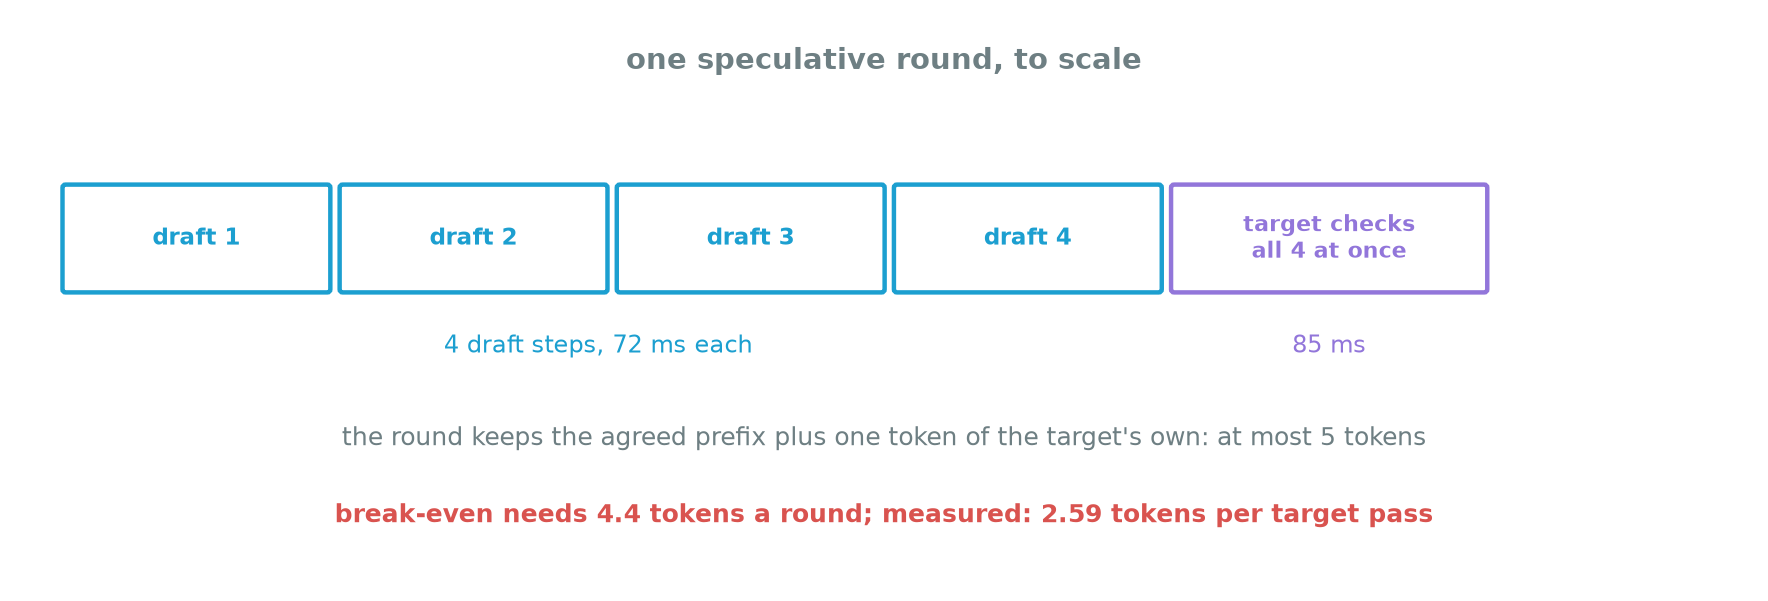

*Figure 9.11 — One speculative round, drawn to the measured step times. The draft proposes 4 tokens at 72 ms each, and the 1.5B model checks them in one pass of about 85 ms. The round pays off only if it yields 4.4 tokens, and the most it can yield is 5; the measured average is 2.59 tokens per target pass.*

The draft's tokens are accepted 40% of the time, so each pass of the 1.5B model yields 2.6 tokens on average instead of one. Even so, generation with the draft is slower: 0.51 times the speed of the 1.5B alone. The last printed line explains it from the measured step times. A round costs 4 draft steps (72 ms each) and one target pass (85 ms), so it pays off only if it yields 4.4 tokens, close to the maximum of 5. On this machine a step of the small model costs nearly as much as a step of the large one, because both are dominated by the same per-step overhead (section 2). Speculative decoding pays when the draft is much cheaper per step than the target: a much larger target, or a draft that is compiled or runs on idle hardware.

The last two columns show where the outputs first differ from the 1.5B model's own greedy output. In exact arithmetic they would never differ. Hugging Face's version matches it fully on four prompts and drifts after 10 to 112 tokens on the others; our loop drifts after 4 to 21 tokens. The reason is bf16 rounding: our loop checks the draft with a fresh pass over the whole sequence, and the 1.5B model alone, run that way instead of with its cache, also switches from "an important hyperparameter" to "a hyperparameter" at the fourth token. Greedy decoding is only as repeatable as the arithmetic underneath it.

## What to take away

- The KV cache turns each decoding step from a pass over the whole sequence into a pass over one token. Its size is 2 × layers × key/value heads × head size × bytes per token, and grouped-query attention cuts it several times over.
- Prefill is fast and parallel; decoding is one token at a time. At batch 1 the GPU mostly waits, which is why batching many requests costs little extra time per step.
- Eager decoding of small models is limited by per-step overhead, not by memory bandwidth; compiling removes most of it.
- Fused attention kernels give the same result with memory that grows linearly with length instead of quadratically.
- Weight quantisation is cheap at 8 bits; at 4 bits it depends on how many weights share a scale, because of outliers.
- Speculative decoding helps only when a draft step is much cheaper than a target step. Work out the break-even from measured times before relying on it.

---

# Going deeper

Reading for after the session.

## Attention kernels

Dao et al. (2022), *FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness*, computes attention in tiles that fit in the GPU's fast on-chip memory, keeping running softmax statistics, so the full score matrix is never written to main memory. PyTorch's `scaled_dot_product_attention` chooses between such kernels automatically.

## Serving

Kwon et al. (2023), *Efficient Memory Management for Large Language Model Serving with PagedAttention*, the paper behind vLLM, stores the KV cache in fixed-size blocks like pages of virtual memory, so many requests of different lengths can share GPU memory without waste, and combines this with continuous batching.

## Grouped-query attention

Ainslie et al. (2023), *GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints*, showed that sharing each key/value head among several query heads keeps nearly all the quality of full multi-head attention while shrinking the cache. Multi-query attention, with a single key/value head, is the extreme case.

## Quantisation

Dettmers et al. (2022), *LLM.int8()*, found that a few feature dimensions carry very large values in large models and kept them in 16 bits. Frantar et al. (2023), *GPTQ*, rounds weights one at a time and adjusts the remaining ones to compensate, using a small calibration set; Lin et al. (2024), *AWQ*, scales the most important weight channels before rounding. All of them beat the round-to-nearest of section 4 at 4 bits.

## Speculative decoding

Leviathan, Kalman and Matias (2023), *Fast Inference from Transformers via Speculative Decoding*, and Chen et al. (2023), *Accelerating Large Language Model Decoding with Speculative Sampling*, introduced the method, including a version for sampling that keeps the target model's output distribution exactly. Reported speed-ups of two to three times use targets far larger than their drafts.